# Pipeline de classificação de risco de crédito

Este notebook simula um cenário em que uma instituição deseja **treinar um modelo supervisionado** para apoiar decisões de concessão de crédito, utilizando dados são **sintéticos**.

O objetivo é estimar, com base em variáveis de perfil e solicitação, se o tomador do crédito tende a representar **maior ou menor risco** de inadimplência (rótulo binário).

O notebook desenvolve o ciclo mínimo de um modelo de predição: dados → pré-processamento → treino → validação → interpretação → uso em decisão simulada.

## 1 Dependências e configuração

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2 Geração de dados sintéticos

Simulamos uma base com variáveis comuns em análise de crédito e um rótulo `inadimplente` (1 = houve default no período observado, 0 = adimplente). A relação entre variáveis e rótulo é propositalmente ruidosa, como em dados reais.

In [13]:
def generate_credit_risk_base(n_amostras: int = 5000, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    
    rng                = np.random.default_rng(random_state)
    n                  = n_amostras
    idade              = rng.integers(22, 66, size=n)
    renda_mensal       = rng.lognormal(mean=np.log(3500), sigma=0.45, size=n).round(2)
    tempo_emprego_anos = rng.exponential(scale=4, size=n).clip(0, 35).round(1)
    score_interno      = rng.normal(650, 90, size=n).clip(300, 900).astype(int)
    valor_solicitado   = rng.lognormal(mean=np.log(8000), sigma=0.6, size=n).round(2)
    num_parcelas       = rng.choice([6, 12, 18, 24, 36, 48], size=n, p=[0.1, 0.25, 0.2, 0.2, 0.15, 0.1])
    tipo_renda         = rng.choice(["CLT", "autonomo", "aposentado"], size=n, p=[0.65, 0.22, 0.13])
    possui_restricao   = rng.choice(["sim", "nao"], size=n, p=[0.12, 0.88])

    # probabilidade base de default (logit simplificado)
    z            = (-3.2 
                    - 0.025   * (score_interno - 650)
                    - 0.00008 * renda_mensal
                    + 0.00002 * valor_solicitado
                    + 0.015   * (num_parcelas / 12)
                    - 0.04    * tempo_emprego_anos)
    z            = np.asarray(z, dtype=float)
    z           += np.where(possui_restricao == "sim", 0.85, 0)
    z           += np.where(tipo_renda == "autonomo", 0.35, 0)
    z           += rng.normal(0, 0.35, size=n)
    p_default    = 1 / (1 + np.exp(-z))
    inadimplente = rng.binomial(1, p_default)

    return pd.DataFrame(
        {
            "idade":              idade,
            "renda_mensal":       renda_mensal,
            "tempo_emprego_anos": tempo_emprego_anos,
            "score_interno":      score_interno,
            "valor_solicitado":   valor_solicitado,
            "num_parcelas":       num_parcelas,
            "tipo_renda":         tipo_renda,
            "possui_restricao":   possui_restricao,
            "inadimplente":       inadimplente,
        }
    )


df = generate_credit_risk_base(6000)
print(df.shape)
df.head()

(6000, 9)


,idade,renda_mensal,tempo_emprego_anos,score_interno,valor_solicitado,num_parcelas,tipo_renda,possui_restricao,inadimplente
0,25,5630.15,0.3,501,5234.99,24,CLT,nao,0
1,56,2491.57,9.6,593,8264.73,18,CLT,sim,0
2,50,1020.17,1.0,695,12435.70,12,CLT,nao,0
3,41,1580.32,11.7,527,14883.12,48,CLT,nao,0
4,41,6635.91,2.7,618,12856.88,24,CLT,nao,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               6000 non-null   int64  
 1   renda_mensal        6000 non-null   float64
 2   tempo_emprego_anos  6000 non-null   float64
 3   score_interno       6000 non-null   int64  
 4   valor_solicitado    6000 non-null   float64
 5   num_parcelas        6000 non-null   int64  
 6   tipo_renda          6000 non-null   str    
 7   possui_restricao    6000 non-null   str    
 8   inadimplente        6000 non-null   int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 469.0 KB


In [5]:
df['inadimplente'].value_counts(normalize=True)

inadimplente
0    0.8795
1    0.1205
Name: proportion, dtype: float64

## 3 Separação treino/teste e pré-processamento

Usamos `ColumnTransformer` para tratar colunas numéricas e categóricas de forma unificada e evitar vazamento de informação do conjunto de teste para o treino (tudo fica dentro do `Pipeline`).

In [6]:
# seleciona features
TARGET   = "inadimplente"
FEATURES = [c for c in df.columns if c != TARGET]
x        = df[FEATURES]
y        = df[TARGET]

# separa colunas numericas e categoricas
num_cols = df[FEATURES].select_dtypes(include='number').columns
cat_cols = [f for f in FEATURES if f not in num_cols]

# separa dados de treino e teste, seguindo proporcao de casos positivos e negativos do target
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

numeric_pipe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")), # imputa valores faltantes com a mediana
        ("scaler", StandardScaler()),                  # reescala variaveis: padroniza as colunas para terem media 0 e desvio padrao 1
    ]
)

categorical_pipe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")), # imputa valores faltantes com a moda
        ("onehot", OneHotEncoder(handle_unknown="ignore")),   # converte variaveis categoricas em variaveis dummy (0 ou 1), criando uma coluna para cada categoria
    ]
)

# combina os pipelines de variaveis numericas e categoricas em um unico pipeline
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ]
)

x_train.shape, x_test.shape

((4500, 8), (1500, 8))

## 4 Modelo baseline - Pipeline do classificador

Vamos partir de um modelo de **Regressão Logística**, por ser rápido e interpretável (via coeficientes). Outras alternativas comuns em produção incluem _Random Forest_ e _Gradient Boosting_.

Encadeamos o pré-processamento com o treinamento e teste do modelo. 

In [8]:
clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)

model_pipe = Pipeline(
    steps=[
        ("prep", preprocess),
        ("model", clf),
    ]
)

model_pipe.fit(x_train, y_train)
y_proba = model_pipe.predict_proba(x_test)[:, 1]
y_pred  = model_pipe.predict(x_test)

print("ROC-AUC (teste):", round(roc_auc_score(y_test, y_proba), 4))

ROC-AUC (teste): 0.9036


In [9]:
# validacao cruzada
cv     = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(model_pipe, x_train, y_train, cv=cv, scoring="roc_auc")
print("ROC-AUC por fold:", scores.round(4))
print("Media ± desvio:", f"{scores.mean():.4f} ± {scores.std():.4f}")

ROC-AUC por fold: [0.9179 0.887  0.8969 0.9207 0.9   ]
Media ± desvio: 0.9045 ± 0.0128


## 5. Avaliação no conjunto de teste

              precision    recall  f1-score   support

  adimplente       0.97      0.82      0.89      1319
inadimplente       0.39      0.82      0.53       181

    accuracy                           0.82      1500
   macro avg       0.68      0.82      0.71      1500
weighted avg       0.90      0.82      0.85      1500



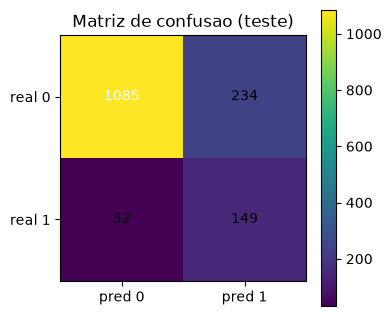

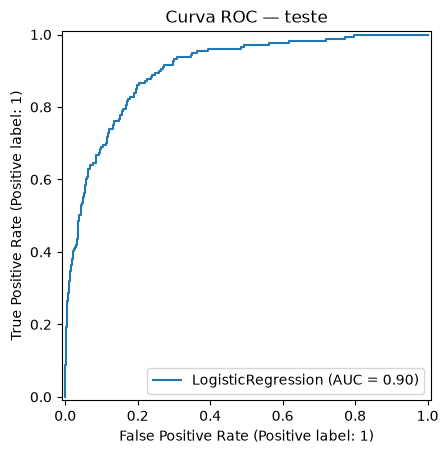

In [10]:
print(classification_report(y_test, y_pred, target_names=["adimplente", "inadimplente"]))

cm      = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 3.5))
im      = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["pred 0", "pred 1"])
ax.set_yticklabels(["real 0", "real 1"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")

ax.set_title("Matriz de confusao (teste)")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba, name="LogisticRegression")
plt.title("Curva ROC — teste")
plt.show()

## 6. Explicabilidade simplificada (coeficientes na escala padronizada)

Após `StandardScaler`, os coeficientes da regressão logística indicam a direção do efeito sobre o log-odds de inadimplência. Isso **não substitui** ferramentas como SHAP em modelos mais complexos, mas ajuda na comunicação com negócio.

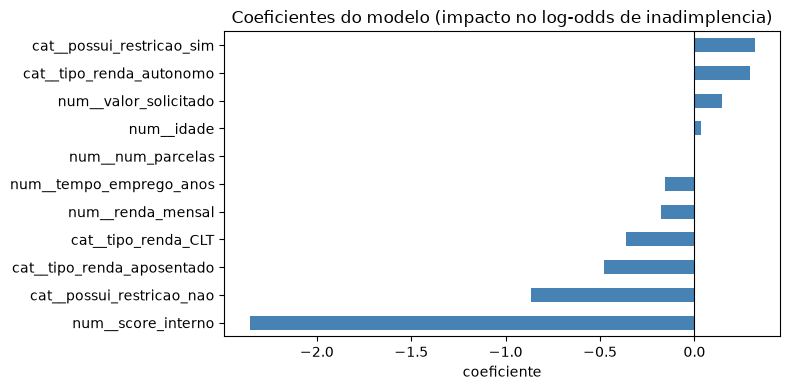

(num__score_interno           -2.355780
 cat__possui_restricao_nao    -0.864320
 cat__tipo_renda_aposentado   -0.477842
 cat__tipo_renda_CLT          -0.362248
 num__renda_mensal            -0.174775
 num__tempo_emprego_anos      -0.157154
 num__num_parcelas             0.005417
 num__idade                    0.035090
 dtype: float64,
 cat__tipo_renda_CLT         -0.362248
 num__renda_mensal           -0.174775
 num__tempo_emprego_anos     -0.157154
 num__num_parcelas            0.005417
 num__idade                   0.035090
 num__valor_solicitado        0.144319
 cat__tipo_renda_autonomo     0.295261
 cat__possui_restricao_sim    0.319492
 dtype: float64)

In [11]:
prep          = model_pipe.named_steps["prep"]
feature_names = prep.get_feature_names_out()
model         = model_pipe.named_steps["model"]
coefs         = pd.Series(model.coef_.ravel(), index=feature_names).sort_values()

plt.figure(figsize=(8, 4))
coefs.plot(kind="barh", color="steelblue")
plt.axvline(0, color="k", linewidth=0.8)
plt.title("Coeficientes do modelo (impacto no log-odds de inadimplencia)")
plt.xlabel("coeficiente")
plt.tight_layout()
plt.show()

coefs.head(8), coefs.tail(8)

## 7. Simula predição para um novo perfil

In [21]:
novo = pd.DataFrame(
    [
        {
            "idade": 34,
            "renda_mensal": 4200.0,
            "tempo_emprego_anos": 5.0,
            "score_interno": 620,
            "valor_solicitado": 12000.0,
            "num_parcelas": 24,
            "tipo_renda": "CLT",
            "possui_restricao": "nao",
        }
    ]
)

p = model_pipe.predict_proba(novo)[0, 1]
print(f"Probabilidade estimada de inadimplencia: {p:.1%}")
print("Rotulo binario (limiar 0.5):", int(model_pipe.predict(novo)[0]))

Probabilidade estimada de inadimplencia: 27.2%
Rotulo binario (limiar 0.5): 0


A saída `predict_proba` pode ser comparada a **políticas** (por exemplo: aprovar se probabilidade de default < 25%, ou encaminhar para análise manual em faixas intermediárias).

O exemplo acima recebeu do modelo uma probabilidade de inadimplência de $27,2\%$, ou seja, seu crédito não foi aprovado na primeira análise, mas pode ser enviado para uma segunda análise manual.